# DSC 411/511 Project
# Notebook 04: RQ2: Can We Flag Large Losses Before the Adjuster Arrives?

**Class topics:** Lecture 07 (imbalanced targets: "Luxury = top 10%", confusion matrix, precision,
recall, moving the threshold, ROC, fixing imbalance), Lecture 05 (trees), Lecture 04 (feature ranking).

---

> **RQ2. Can we flag claims whose building damage is above a "large loss" line, using only facts known
> about the building, the policy and the storm?**

**Why it matters.** After a hurricane, thousands of claims arrive in a few days. The few very large losses
need the most experienced adjusters, early advance payments, and often a substantial-damage decision
(which triggers rebuilding rules and Increased Cost of Compliance coverage). A good flag at filing time
would help to send the right adjuster to the right house first.

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, f1_score)
import lightgbm as lgb
import shap
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
large_loss_line = json.load(open(TABLE_DIR / 'large_loss_definition.json'))['large_loss_line_usd']
print(f'Large-loss line from notebook 01: ${large_loss_line:,.0f}')

Large-loss line from notebook 01: $143,519


---
# Section 1: Where Should the "Large Loss" Line Be?

## 1.1 Damage, not payment

We define the line on **building damage** (`buildingDamageAmount`), not on the payment. The payment is
damage minus the deductible, cut off at the coverage limit (250,000 dollars for most homes). So a payment
line would partly measure the **policy**, not the **flood**. Damage measures the physical loss.

## 1.2 Looking at the distribution (training years only)

In [2]:
damage_known = claims[claims['buildingDamageAmount'].notna()].copy()
train_damage = damage_known.loc[damage_known['loss_year'].isin(TRAIN_YEARS), 'buildingDamageAmount']
positive_train_damage = train_damage[train_damage > 0]
percentile_table = pd.DataFrame({'percentile': [50, 75, 80, 90, 95, 99]})
percentile_table['damage_usd'] = [positive_train_damage.quantile(p / 100) for p in percentile_table['percentile']]
total_damage = positive_train_damage.sum()
percentile_table['share_of_all_damage_above_%'] = [positive_train_damage[positive_train_damage > v].sum() / total_damage * 100
                                                   for v in percentile_table['damage_usd']]
print(f'Positive-damage claims 2020-2023: {len(positive_train_damage):,}')
print(percentile_table.round(1).to_string(index=False))

Positive-damage claims 2020-2023: 123,806
 percentile  damage_usd  share_of_all_damage_above_%
         50     26553.5                         92.3
         75     78033.0                         73.2
         80     92452.0                         66.6
         90    143519.0                         49.1
         95    217561.0                         35.7
         99    535313.0                         17.1


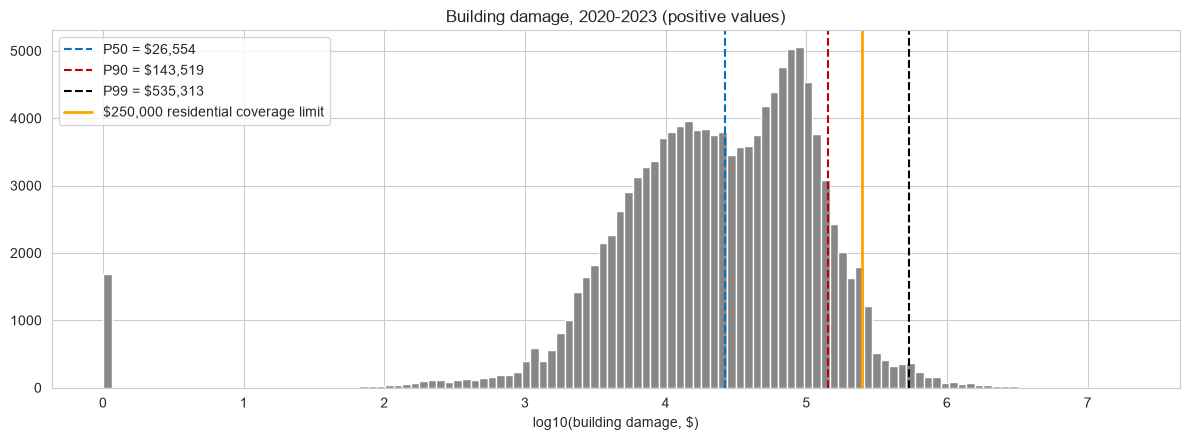

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(np.log10(positive_train_damage), bins=120, color='#888888')
for p, color in [(50, '#0070C0'), (90, '#C00000'), (99, 'black')]:
    value = positive_train_damage.quantile(p / 100)
    ax.axvline(np.log10(value), color=color, ls='--', label=f'P{p} = ${value:,.0f}')
ax.axvline(np.log10(250_000), color='orange', lw=2, label='$250,000 residential coverage limit')
ax.set_xlabel('log10(building damage, $)')
ax.set_title('Building damage, 2020-2023 (positive values)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_damage_distribution_line.png', dpi=120)
plt.show()

**Why the 90th percentile?**
1. It is the same "top 10%" idea as the `Luxury` target in Lecture 07, so the method is familiar.
2. The top 10% of claims carry a large share of all damage dollars (see the table): it is where the money is.
3. It sits below the 250,000 dollar coverage limit, so the target is not just "the house was big enough to hit the cap".
4. It is learned on the **training years only**, so the test years cannot move the line (no leakage).

**A second line from FEMA itself.** FEMA calls a building **substantially damaged** when the damage is at
least 50% of the building's market value. Then it must be rebuilt to current flood rules. We test this line
too (Section 9), with the adjuster's pre-flood value as the denominator. The denominator is only used to
build the target, never as a feature.

In [4]:
print('Large-loss rate by year (%), among claims with recorded damage:')
rate_table = damage_known.groupby('loss_year').agg(claims=('id', 'size'), large_loss_pct=('large_loss_flag', 'mean'),
                                                   substantial_damage_pct=('substantial_damage_flag', 'mean'))
rate_table[['large_loss_pct', 'substantial_damage_pct']] *= 100
print(rate_table.round(1).to_string())

Large-loss rate by year (%), among claims with recorded damage:
           claims  large_loss_pct  substantial_damage_pct
loss_year                                                
2020        27720             2.5                     6.8
2021        39802             4.9                    10.5
2022        49851            17.5                    22.3
2023        18083             5.4                    11.3
2024        88530            18.3                    23.8
2025        11134             7.3                    12.3


The rate is much higher in 2024 (Helene and Milton) than in the training years. Our model will be tested on a
year that is **worse** than anything it trained on. That is a hard but honest test.

---
# Section 2: Data for RQ2

In [5]:
TARGET = 'large_loss_flag'
damage_known[TARGET] = damage_known[TARGET].astype(int)
train_claims = damage_known[damage_known['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_claims = damage_known[damage_known['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
print(f'Train: {len(train_claims):,} claims, {train_claims[TARGET].mean() * 100:.1f}% large')
print(f'Test : {len(test_claims):,} claims, {test_claims[TARGET].mean() * 100:.1f}% large')
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    check_no_leakage(numeric + categorical)
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']

Train: 135,456 claims, 9.1% large
Test : 99,664 claims, 17.0% large


---
# Section 3: Fixing Imbalance (Lecture 07, Section 12)

With about 1 positive in 10, a model can reach 90% accuracy by never flagging anything. Three standard fixes:

| Fix | What it does |
|---|---|
| **class weights** | errors on the rare class cost more in the loss function (`class_weight='balanced'`) |
| **undersampling** | train on all positives and a random subset of negatives |
| **threshold moving** | keep the model, but flag at a lower probability than 0.5 |

Important: class weights and undersampling change the **scores**, but ROC-AUC and PR-AUC only look at the
**ranking**. We therefore also report precision and recall at the default 0.5 cut.

In [6]:
def fit_lightgbm(train_rows, numeric, categorical, class_weight=None, n_estimators=600, target=TARGET):
    model = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, num_leaves=63, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                               class_weight=class_weight, random_state=SEED, verbose=-1)
    model.fit(to_category_frame(train_rows, numeric, categorical), train_rows[target])
    return model


def evaluate(name, y_true, scores, cut=0.5):
    predicted = (scores >= cut).astype(int)
    return {'setting': name, 'ROC_AUC': roc_auc_score(y_true, scores), 'PR_AUC': average_precision_score(y_true, scores),
            'lift_top10%': lift_at_top(y_true, scores, 0.10),
            'precision@0.5': precision_score(y_true, predicted, zero_division=0),
            'recall@0.5': recall_score(y_true, predicted)}


imbalance_rows = []
test_frame_C = to_category_frame(test_claims, numeric_C, categorical_C)
model_plain = fit_lightgbm(train_claims, numeric_C, categorical_C)
imbalance_rows.append(evaluate('no fix', test_claims[TARGET], model_plain.predict_proba(test_frame_C)[:, 1]))
model_weighted = fit_lightgbm(train_claims, numeric_C, categorical_C, class_weight='balanced')
imbalance_rows.append(evaluate('class_weight = balanced', test_claims[TARGET], model_weighted.predict_proba(test_frame_C)[:, 1]))
positives = train_claims[train_claims[TARGET] == 1]
negatives = train_claims[train_claims[TARGET] == 0].sample(len(positives) * 2, random_state=SEED)
undersampled = pd.concat([positives, negatives])
model_under = fit_lightgbm(undersampled, numeric_C, categorical_C)
imbalance_rows.append(evaluate('undersample negatives to 2:1', test_claims[TARGET], model_under.predict_proba(test_frame_C)[:, 1]))
imbalance_table = pd.DataFrame(imbalance_rows).round(4)
print(f'Random PR-AUC = positive share in test = {test_claims[TARGET].mean():.3f}')
print(imbalance_table.to_string(index=False))

Random PR-AUC = positive share in test = 0.170
                     setting  ROC_AUC  PR_AUC  lift_top10%  precision@0.5  recall@0.5
                      no fix   0.8227  0.4680       3.0185         0.7043      0.0576
     class_weight = balanced   0.8138  0.4558       2.8885         0.5062      0.2725
undersample negatives to 2:1   0.8159  0.4542       2.9820         0.5418      0.2509


The ranking metrics barely move. The precision/recall at 0.5 move a lot: the fixes mainly **shift the
threshold**. In the rest of the notebook we keep the plain model and choose the threshold on purpose
(Section 7), which is the cleanest of the three fixes.

---
# Section 4: Course Models on RQ2

In [7]:
model_rows = []
sample_train = train_claims.sample(min(60_000, len(train_claims)), random_state=SEED)
course_models = {
    'Gaussian naive Bayes': GaussianNB(),
    'Decision tree (depth 8, balanced)': DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight='balanced', random_state=SEED),
    'Logistic regression (balanced)': LogisticRegression(max_iter=3000, C=0.5, class_weight='balanced'),
    'Neural network (MLP 64-32)': MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512, early_stopping=True,
                                                max_iter=60, random_state=SEED),
}
for model_name, estimator in course_models.items():
    pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)), ('model', estimator)])
    training_rows = sample_train if model_name == 'Gaussian naive Bayes' else train_claims
    pipeline.fit(training_rows, training_rows[TARGET])
    model_rows.append(evaluate(model_name, test_claims[TARGET], pipeline.predict_proba(test_claims)[:, 1]))
model_rows.append(evaluate('LightGBM (no fix)', test_claims[TARGET], model_plain.predict_proba(test_frame_C)[:, 1]))
model_table = pd.DataFrame(model_rows).round(4)
model_table.to_csv(TABLE_DIR / '04_rq2_model_comparison.csv', index=False)
print(model_table.to_string(index=False))

                          setting  ROC_AUC  PR_AUC  lift_top10%  precision@0.5  recall@0.5
             Gaussian naive Bayes   0.6749  0.2500       2.2816         0.2174      0.8915
Decision tree (depth 8, balanced)   0.6915  0.3099       2.2362         0.4178      0.2189
   Logistic regression (balanced)   0.7803  0.3732       2.3887         0.3480      0.4274
       Neural network (MLP 64-32)   0.7878  0.4031       2.6818         0.6021      0.0991
                LightGBM (no fix)   0.8227  0.4680       3.0185         0.7043      0.0576


---
# Section 5: The Progression: NFIP Only vs NFIP + External Data

In [8]:
progression_rows = []
progression_scores = {}
progression_models = {}
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    model = fit_lightgbm(train_claims, numeric, categorical)
    scores = model.predict_proba(to_category_frame(test_claims, numeric, categorical))[:, 1]
    progression_scores[set_name] = scores
    progression_models[set_name] = model
    logistic = Pipeline([('prep', make_preprocessor(numeric, categorical)),
                         ('model', LogisticRegression(max_iter=3000, C=0.5, class_weight='balanced'))])
    logistic.fit(train_claims, train_claims[TARGET])
    logistic_scores = logistic.predict_proba(test_claims)[:, 1]
    row = evaluate(set_name, test_claims[TARGET], scores)
    row['Logistic_PR_AUC'] = average_precision_score(test_claims[TARGET], logistic_scores)
    row['Logistic_ROC_AUC'] = roc_auc_score(test_claims[TARGET], logistic_scores)
    progression_rows.append(row)
progression_table = pd.DataFrame(progression_rows).rename(columns={'setting': 'feature_set'}).round(4)
progression_table.to_csv(TABLE_DIR / '04_rq2_progression.csv', index=False)
print(f'Test positives: {test_claims[TARGET].mean() * 100:.1f}%  (random PR-AUC)')
print(progression_table.drop(columns=['precision@0.5', 'recall@0.5']).to_string(index=False))

Test positives: 17.0%  (random PR-AUC)
                            feature_set  ROC_AUC  PR_AUC  lift_top10%  Logistic_PR_AUC  Logistic_ROC_AUC
                           A. NFIP only   0.8117  0.4112       2.5712           0.3865            0.7822
B. NFIP + event (PRISM, HURDAT2, coast)   0.8047  0.4457       2.9220           0.3706            0.7736
   C. NFIP + event + context (ACS, NRI)   0.8227  0.4680       3.0185           0.3732            0.7803


## 5.1 Event-grouped cross-validation (2020-2023)

In [9]:
group_cv = GroupKFold(n_splits=5)
cv_rows = []
for set_name in FEATURE_SETS:
    numeric, categorical = FEATURE_SETS[set_name]
    fold_pr, fold_roc = [], []
    for fit_index, validation_index in group_cv.split(train_claims, groups=train_claims['event_group']):
        fit_rows, validation_rows = train_claims.iloc[fit_index], train_claims.iloc[validation_index]
        model = fit_lightgbm(fit_rows, numeric, categorical, n_estimators=300)
        scores = model.predict_proba(to_category_frame(validation_rows, numeric, categorical))[:, 1]
        fold_pr.append(average_precision_score(validation_rows[TARGET], scores) / validation_rows[TARGET].mean())
        fold_roc.append(roc_auc_score(validation_rows[TARGET], scores))
    cv_rows.append({'feature_set': set_name, 'ROC_AUC_mean': np.mean(fold_roc), 'ROC_AUC_std': np.std(fold_roc),
                    'PR_AUC_over_random_mean': np.mean(fold_pr)})
cv_table = pd.DataFrame(cv_rows).round(3)
cv_table.to_csv(TABLE_DIR / '04_rq2_event_grouped_cv.csv', index=False)
print('PR_AUC_over_random = PR-AUC divided by the positive share of that fold (1.0 = random)')
print(cv_table.to_string(index=False))

PR_AUC_over_random = PR-AUC divided by the positive share of that fold (1.0 = random)
                            feature_set  ROC_AUC_mean  ROC_AUC_std  PR_AUC_over_random_mean
                           A. NFIP only         0.825        0.029                    5.249
B. NFIP + event (PRISM, HURDAT2, coast)         0.830        0.040                    5.897
   C. NFIP + event + context (ACS, NRI)         0.838        0.038                    5.996


## 5.2 Is the gain real? An event-block bootstrap

Some gaps in the table above are small (ROC-AUC A vs C), and set B is even *below* A in ROC-AUC. A single test number
has no uncertainty, and claims from one storm are not independent. So we put a 95% confidence interval on the
**gain over NFIP-only**, resampling **whole events** (the helper `event_block_bootstrap` in `nfip_project_utils.py`,
500 repeats). If the interval is above 0, the gain does not depend on a few lucky storms.

In [10]:
test_claims['score_A'] = progression_scores['A. NFIP only']
test_claims['score_B'] = progression_scores['B. NFIP + event (PRISM, HURDAT2, coast)']
test_claims['score_C'] = progression_scores['C. NFIP + event + context (ACS, NRI)']
large_loss_metric_functions = {'ROC_AUC': roc_auc_score, 'PR_AUC': average_precision_score,
                               'lift_top10%': lambda y, s: lift_at_top(y, s, 0.10)}
bootstrap_table = event_block_bootstrap(test_claims, TARGET, {'A. NFIP only': 'score_A', 'B. + event': 'score_B', 'C. + event + context': 'score_C'},
                                        large_loss_metric_functions, baseline='A. NFIP only', n_repeats=500).round(4)
bootstrap_table.to_csv(TABLE_DIR / '04_rq2_bootstrap.csv', index=False)
print(f"Events resampled: {bootstrap_table['events'].iloc[0]}, valid repeats: {bootstrap_table['valid_repeats'].iloc[0]}")
print(bootstrap_table.drop(columns=['events', 'valid_repeats']).to_string(index=False))

Events resampled: 26, valid repeats: 500
     metric                model  value  gain_vs_baseline  ci_95_low  ci_95_high  share_of_repeats_with_gain_%
    ROC_AUC         A. NFIP only 0.8117               NaN        NaN         NaN                           NaN
    ROC_AUC           B. + event 0.8047           -0.0070    -0.0109      0.0393                          54.4
    ROC_AUC C. + event + context 0.8227            0.0110     0.0092      0.0414                         100.0
     PR_AUC         A. NFIP only 0.4112               NaN        NaN         NaN                           NaN
     PR_AUC           B. + event 0.4457            0.0345     0.0314      0.0677                         100.0
     PR_AUC C. + event + context 0.4680            0.0568     0.0420      0.0667                         100.0
lift_top10%         A. NFIP only 2.5712               NaN        NaN         NaN                           NaN
lift_top10%           B. + event 2.9220            0.3508     0.1302   

**Reading the bootstrap** (26 event groups, 500 repeats). For **PR-AUC and lift** both B and C beat NFIP-only in
every repeat: PR-AUC gain +0.035 [+0.031, +0.068] for B and +0.057 [+0.042, +0.067] for C; top-10% lift gain +0.35
and +0.45. For **ROC-AUC** the picture is weaker: C gains only +0.011 [+0.009, +0.041], and B is *below* NFIP-only
(-0.007, interval [-0.011, +0.039] contains 0). So the honest claim is: outside data makes the **flag sharper** (more
large losses at the top of the list), but it barely changes the overall ranking, which NFIP coverage and building
facts already do well.

## 5.3 Closed claims only: is the test target noisy?

Notebook 03 (Section 15) found that in 2024-2025 many unpaid claims have **no non-payment reason**. They are most
likely still open. For RQ2 the target is the adjuster's damage, so open claims may have a damage value that is not
final yet. We drop the unpaid claims with a blank `nonPaymentReasonBuilding` from the test years and compare the
scores before and after. (The reason column is used only to choose rows, never as a feature.) We also show the
result without Hurricane Helene, which is about half of the test claims.

In [11]:
probably_open = (test_claims['building_paid_flag'] == 0) & test_claims['nonPaymentReasonBuilding'].isna()
print(f'Test claims that are unpaid with a blank reason (probably open): {probably_open.sum():,} '
      f'({probably_open.mean() * 100:.1f}% of {len(test_claims):,})')
closed_versions = {'all test claims': test_claims, 'closed claims only': test_claims[~probably_open],
                   'closed claims, without Helene': test_claims[~probably_open & (test_claims['event_group'] != 'Hurricane Helene')]}
closed_rows = []
for version, data in closed_versions.items():
    for set_name, column in [('A. NFIP only', 'score_A'), ('B. + event', 'score_B'), ('C. + event + context', 'score_C')]:
        closed_rows.append({'test_set': version, 'claims': len(data), 'large_loss_rate': data[TARGET].mean(), 'feature_set': set_name,
                            'ROC_AUC': roc_auc_score(data[TARGET], data[column]),
                            'PR_AUC': average_precision_score(data[TARGET], data[column]),
                            'lift_top10%': lift_at_top(data[TARGET], data[column], 0.10)})
closed_table = pd.DataFrame(closed_rows).round(4)
closed_table.to_csv(TABLE_DIR / '04_rq2_closed_claims.csv', index=False)
print(closed_table.to_string(index=False))

Test claims that are unpaid with a blank reason (probably open): 1,404 (1.4% of 99,664)


                     test_set  claims  large_loss_rate          feature_set  ROC_AUC  PR_AUC  lift_top10%
              all test claims   99664           0.1705         A. NFIP only   0.8117  0.4112       2.5712
              all test claims   99664           0.1705           B. + event   0.8047  0.4457       2.9220
              all test claims   99664           0.1705 C. + event + context   0.8227  0.4680       3.0185
           closed claims only   98260           0.1726         A. NFIP only   0.8109  0.4133       2.5619
           closed claims only   98260           0.1726           B. + event   0.8041  0.4484       2.9103
           closed claims only   98260           0.1726 C. + event + context   0.8220  0.4703       3.0017
closed claims, without Helene   46242           0.0717         A. NFIP only   0.7877  0.2419       3.7438
closed claims, without Helene   46242           0.0717           B. + event   0.8183  0.3006       4.2656
closed claims, without Helene   46242         

**Reading the check.** Only 1,404 test claims (1.4%) are unpaid with a blank reason. Dropping them changes PR-AUC by
about +0.002 for every feature set (C: 0.468 -> 0.470), so open claims do not bias RQ2. **Without Helene** the task
is harder (large-loss rate lower, PR-AUC 0.24-0.30), but the outside data helps *more*: PR-AUC 0.242 (A) -> 0.302
(C), and now even ROC-AUC improves clearly (0.788 -> 0.820). The gain is not a Helene effect.

## 5.4 Which outside source makes the gain? Feature-block ablation

We remove one block of outside features at a time from set B (rain, storm, coast distance) and retrain.

In [12]:
ablation_sets = {
    'B without rain (PRISM)': NFIP_NUMERIC_FEATURES + STORM_FEATURES + COAST_FEATURES,
    'B without storm (HURDAT2)': NFIP_NUMERIC_FEATURES + RAIN_FEATURES + COAST_FEATURES,
    'B without coast distance': NFIP_NUMERIC_FEATURES + RAIN_FEATURES + STORM_FEATURES,
}
ablation_rows = [{'feature_set': 'A. NFIP only', **{k: v for k, v in evaluate('A', test_claims[TARGET], test_claims['score_A']).items() if k in ['ROC_AUC', 'PR_AUC', 'lift_top10%']}},
                 {'feature_set': 'B. NFIP + event (all blocks)', **{k: v for k, v in evaluate('B', test_claims[TARGET], test_claims['score_B']).items() if k in ['ROC_AUC', 'PR_AUC', 'lift_top10%']}}]
for set_name, numeric in ablation_sets.items():
    model = fit_lightgbm(train_claims, numeric, NFIP_CATEGORICAL_FEATURES)
    scores = model.predict_proba(to_category_frame(test_claims, numeric, NFIP_CATEGORICAL_FEATURES))[:, 1]
    ablation_rows.append({'feature_set': set_name, 'ROC_AUC': roc_auc_score(test_claims[TARGET], scores),
                          'PR_AUC': average_precision_score(test_claims[TARGET], scores),
                          'lift_top10%': lift_at_top(test_claims[TARGET], scores, 0.10)})
ablation_table = pd.DataFrame(ablation_rows)
for metric in ['ROC_AUC', 'PR_AUC', 'lift_top10%']:
    ablation_table[f'{metric}_change_vs_full_B'] = ablation_table[metric] - ablation_table.loc[1, metric]
ablation_table = ablation_table.round(4)
ablation_table.to_csv(TABLE_DIR / '04_rq2_ablation.csv', index=False)
print(ablation_table.to_string(index=False))

                 feature_set  ROC_AUC  PR_AUC  lift_top10%  ROC_AUC_change_vs_full_B  PR_AUC_change_vs_full_B  lift_top10%_change_vs_full_B
                A. NFIP only   0.8117  0.4112       2.5712                    0.0070                  -0.0345                       -0.3508
B. NFIP + event (all blocks)   0.8047  0.4457       2.9220                    0.0000                   0.0000                        0.0000
      B without rain (PRISM)   0.8006  0.4343       2.7772                   -0.0041                  -0.0114                       -0.1448
   B without storm (HURDAT2)   0.8050  0.4265       2.6636                    0.0003                  -0.0192                       -0.2584
    B without coast distance   0.8052  0.4446       2.8855                    0.0005                  -0.0011                       -0.0365


**Reading the ablation.** For large losses the **storm block (HURDAT2) matters most**: without it PR-AUC falls by
0.019 and the top-10% lift by 0.26. Without rain PR-AUC falls by 0.011; without coast distance almost nothing changes
(0.001). ROC-AUC hardly moves in any row. This fits the physics: large losses come from strong hurricanes (wind and
surge), while rain decides more about *whether* a claim is paid (RQ1).

---
# Section 6: Reproducing and Extending a Published Finding

**Published claim (Ghaedi et al. style two-stage study, PMC9348728, 2022):** flood-intensity variables are the
most important predictors of NFIP claims, and **state-level models beat a national model**.

We test both on our data:
1. Share of SHAP importance from the event (intensity) features.
2. For Florida (the state with the most claims), compare the national model with a Florida-only model,
   both scored on Florida's 2024-2025 claims.

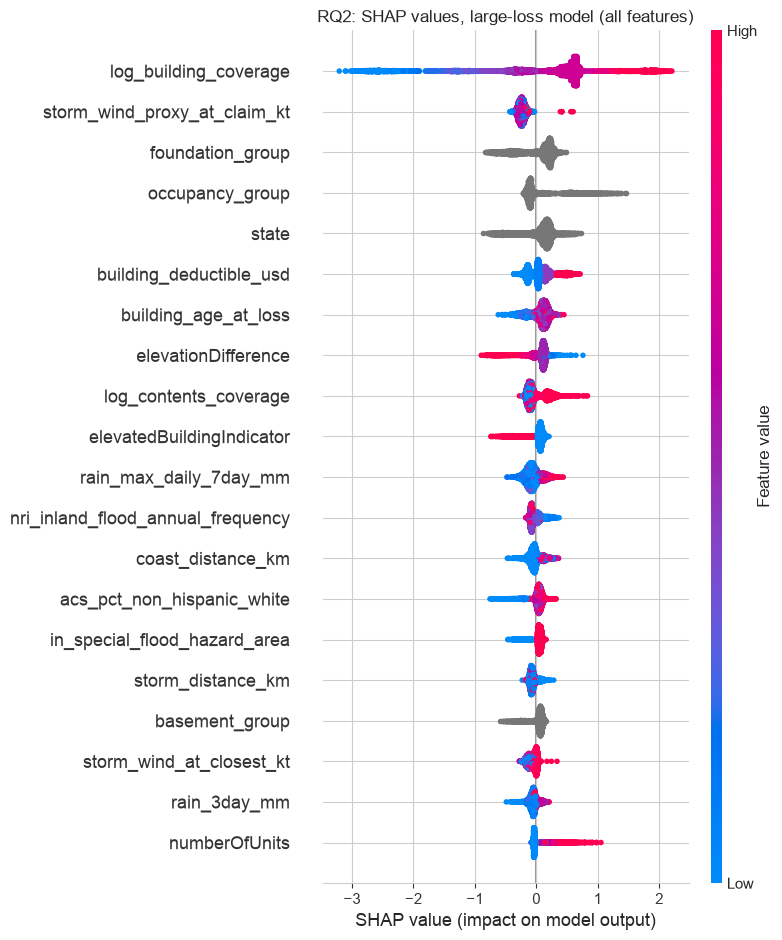

Mean |SHAP| share by data source (%):
NFIP       64.1
context    17.3
event      18.6


In [13]:
model_C = progression_models['C. NFIP + event + context (ACS, NRI)']
shap_rows = to_category_frame(test_claims.sample(5000, random_state=SEED), numeric_C, categorical_C)
shap_values = shap.TreeExplainer(model_C).shap_values(shap_rows)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap.summary_plot(shap_values, shap_rows, max_display=20, show=False)
plt.title('RQ2: SHAP values, large-loss model (all features)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_shap_summary.png', dpi=110)
plt.show()
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_rows.columns).sort_values(ascending=False)
source_of = lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES else 'event' if c in EVENT_FEATURES else 'context'
shap_share = shap_importance.groupby(source_of).sum()
print('Mean |SHAP| share by data source (%):')
print((shap_share / shap_share.sum() * 100).round(1).to_string())
shap_importance.round(4).to_csv(TABLE_DIR / '04_rq2_shap_importance.csv')

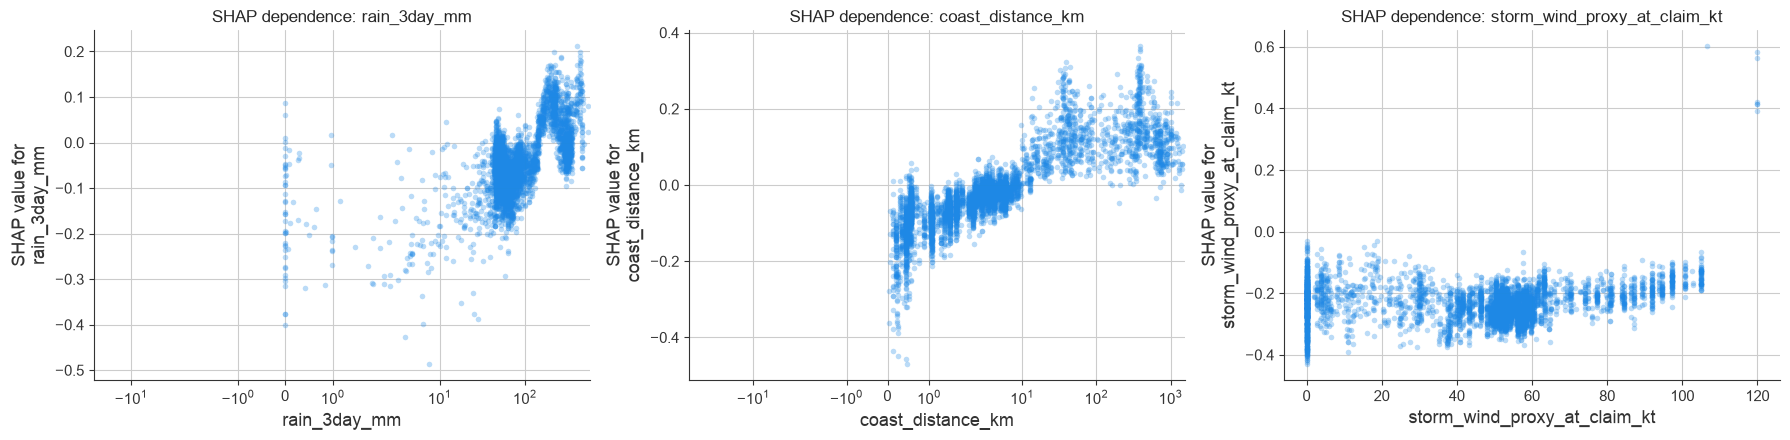

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, feature in zip(axes, ['rain_3day_mm', 'coast_distance_km', 'storm_wind_proxy_at_claim_kt']):
    shap.dependence_plot(feature, shap_values, shap_rows, interaction_index=None, ax=ax, show=False, alpha=0.3)
    if feature != 'storm_wind_proxy_at_claim_kt':
        ax.set_xscale('symlog')
    ax.set_title(f'SHAP dependence: {feature}')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_shap_dependence.png', dpi=110)
plt.show()

In [15]:
state_rows = []
for state in ['FL', 'LA', 'TX', 'NC']:
    state_train = train_claims[train_claims['state'] == state]
    state_test = test_claims[test_claims['state'] == state]
    if state_test[TARGET].sum() < 30 or state_train[TARGET].sum() < 30:
        continue
    numeric_no_state = numeric_C
    categorical_no_state = [c for c in categorical_C if c != 'state']
    state_model = fit_lightgbm(state_train, numeric_no_state, categorical_no_state, n_estimators=400)
    state_scores = state_model.predict_proba(to_category_frame(state_test, numeric_no_state, categorical_no_state))[:, 1]
    national_scores = model_C.predict_proba(to_category_frame(state_test, numeric_C, categorical_C))[:, 1]
    state_rows.append({'state': state, 'train_claims': len(state_train), 'test_claims': len(state_test),
                       'test_large_%': state_test[TARGET].mean() * 100,
                       'national_model_PR_AUC': average_precision_score(state_test[TARGET], national_scores),
                       'state_model_PR_AUC': average_precision_score(state_test[TARGET], state_scores),
                       'national_ROC_AUC': roc_auc_score(state_test[TARGET], national_scores),
                       'state_ROC_AUC': roc_auc_score(state_test[TARGET], state_scores)})
state_table = pd.DataFrame(state_rows).round(3)
state_table.to_csv(TABLE_DIR / '04_rq2_state_vs_national.csv', index=False)
print(state_table.to_string(index=False))

state  train_claims  test_claims  test_large_%  national_model_PR_AUC  state_model_PR_AUC  national_ROC_AUC  state_ROC_AUC
   FL         59721        70651        21.244                  0.489               0.477             0.793          0.780
   LA         21219         3049         2.821                  0.274               0.208             0.899          0.850
   TX          4193         6034         5.535                  0.265               0.193             0.866          0.813
   NC          2585         3631        16.442                  0.484               0.424             0.807          0.741


**Reading the comparison.** Ghaedi et al. (2022) found that state models beat the national model. **We do not
reproduce this.** In all four states the national model has the higher PR-AUC (FL 0.489 vs 0.477, LA 0.274 vs 0.208,
TX 0.265 vs 0.193, NC 0.484 vs 0.424) and the higher ROC-AUC. Our setting is different: claim level instead of
county-event level, and a time split. Our state training sets are small (TX 4,193 claims, NC 2,585), and the national
model borrows strength from other storms. The other half of their finding, that flood-intensity features matter, holds:
rain and storm features are about 19% of the mean |SHAP| (cell above), and adding them raises PR-AUC.

---
# Section 7: Turning Scores into Flags (Lecture 07, Section 8)

Suppose the program can send its senior adjusters to the **top 10%** of new claims by score. We set the
threshold so that 10% of the **2023 validation** claims are flagged, then apply it to 2024-2025.

Threshold (top 10% of 2023 scores): 0.044
Share of 2024-2025 claims flagged : 15.4%
Precision: 0.393   Recall: 0.356   F1: 0.374


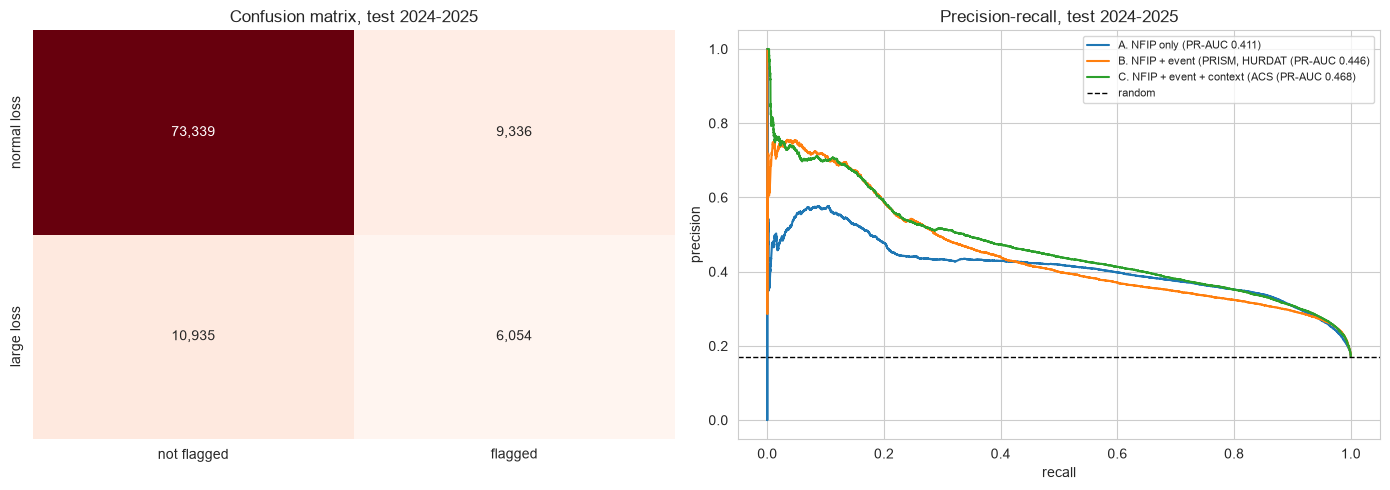

In [16]:
fit_rows = train_claims[train_claims['loss_year'] <= 2022]
validation_rows = train_claims[train_claims['loss_year'] == 2023]
flag_model = fit_lightgbm(fit_rows, numeric_C, categorical_C)
validation_scores = flag_model.predict_proba(to_category_frame(validation_rows, numeric_C, categorical_C))[:, 1]
flag_threshold = float(np.quantile(validation_scores, 0.90))
test_scores = flag_model.predict_proba(test_frame_C)[:, 1]
test_flags = (test_scores >= flag_threshold).astype(int)
print(f'Threshold (top 10% of 2023 scores): {flag_threshold:.3f}')
print(f'Share of 2024-2025 claims flagged : {test_flags.mean() * 100:.1f}%')
print(f'Precision: {precision_score(test_claims[TARGET], test_flags):.3f}   Recall: {recall_score(test_claims[TARGET], test_flags):.3f}   '
      f'F1: {f1_score(test_claims[TARGET], test_flags):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(test_claims[TARGET], test_flags), annot=True, fmt=',', cmap='Reds', cbar=False, ax=axes[0],
            xticklabels=['not flagged', 'flagged'], yticklabels=['normal loss', 'large loss'])
axes[0].set_title('Confusion matrix, test 2024-2025')
for set_name, scores in progression_scores.items():
    precision, recall, _ = precision_recall_curve(test_claims[TARGET], scores)
    axes[1].plot(recall, precision, label=f'{set_name[:30]} (PR-AUC {average_precision_score(test_claims[TARGET], scores):.3f})')
axes[1].axhline(test_claims[TARGET].mean(), color='k', ls='--', lw=1, label='random')
axes[1].set_xlabel('recall')
axes[1].set_ylabel('precision')
axes[1].set_title('Precision-recall, test 2024-2025')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_confusion_pr.png', dpi=120)
plt.show()

**Why recall looks low and is still useful.** 2024 had far more large losses than 2023, so flagging 10% of
claims cannot catch most of them. Read precision instead: among the flagged claims, the share that are truly
large is several times the base rate. Look at recall when more claims can be flagged:

In [17]:
capacity_rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.40]:
    cut = np.quantile(test_scores, 1 - share)
    flagged = test_scores >= cut
    capacity_rows.append({'flag top share': f'{share * 100:.0f}%', 'precision': test_claims[TARGET][flagged].mean(),
                          'recall': test_claims[TARGET][flagged].sum() / test_claims[TARGET].sum(),
                          'lift': test_claims[TARGET][flagged].mean() / test_claims[TARGET].mean()})
print(pd.DataFrame(capacity_rows).round(3).to_string(index=False))

flag top share  precision  recall  lift
            5%      0.539   0.158 3.160
           10%      0.463   0.271 2.715
           20%      0.360   0.423 2.113
           30%      0.317   0.557 1.857
           40%      0.293   0.688 1.720


## 7.1 Can we trust the probabilities? Calibration and the Brier score

A senior adjuster who reads "40% chance of a large loss" should find large losses in about 40% of such claims. We
check this with a reliability curve (10 bins of equal size) and the Brier score (mean squared error of the
probability; lower is better), for the three LightGBM models trained on 2020-2023.

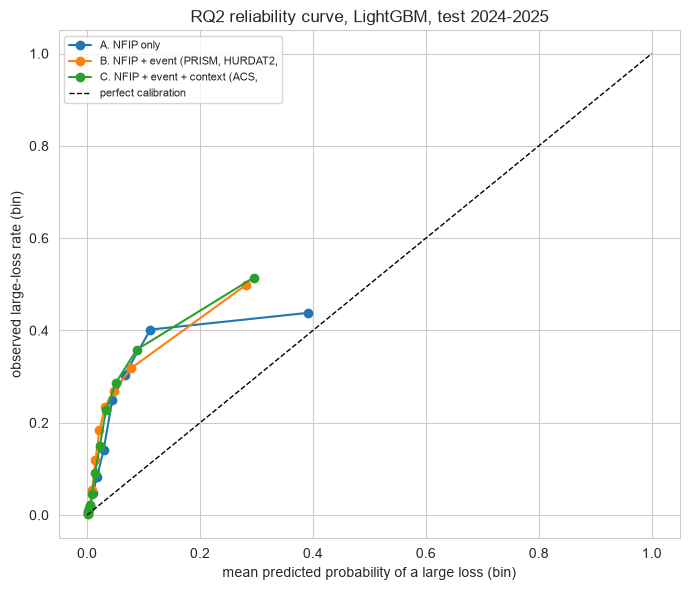

                            feature_set  brier_score  brier_constant_train_rate  mean_predicted  observed_rate  largest_bin_gap
                           A. NFIP only       0.1376                     0.1477          0.0682         0.1705           0.2897
B. NFIP + event (PRISM, HURDAT2, coast)       0.1392                     0.1477          0.0493         0.1705           0.2402
   C. NFIP + event + context (ACS, NRI)       0.1369                     0.1477          0.0522         0.1705           0.2704


In [18]:
calibration_rows = []
fig, ax = plt.subplots(figsize=(7, 6))
training_large_rate = train_claims[TARGET].mean()
for set_name, scores in progression_scores.items():
    observed_rate, mean_predicted = calibration_curve(test_claims[TARGET], scores, n_bins=10, strategy='quantile')
    ax.plot(mean_predicted, observed_rate, 'o-', label=set_name[:32])
    calibration_rows.append({'feature_set': set_name, 'brier_score': brier_score_loss(test_claims[TARGET], scores),
                             'brier_constant_train_rate': brier_score_loss(test_claims[TARGET], np.full(len(scores), training_large_rate)),
                             'mean_predicted': scores.mean(), 'observed_rate': test_claims[TARGET].mean(),
                             'largest_bin_gap': np.abs(observed_rate - mean_predicted).max()})
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect calibration')
ax.set_xlabel('mean predicted probability of a large loss (bin)')
ax.set_ylabel('observed large-loss rate (bin)')
ax.set_title('RQ2 reliability curve, LightGBM, test 2024-2025')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_rq2_calibration.png', dpi=120)
plt.show()
calibration_table = pd.DataFrame(calibration_rows).round(4)
calibration_table.to_csv(TABLE_DIR / '04_rq2_calibration.csv', index=False)
print(calibration_table.to_string(index=False))

**Reading the calibration.** The models learned the 2020-2023 large-loss rate (about 9%), but 17.1% of the 2024-2025
claims were large. The mean predicted probability is only 0.05-0.07, so the curve lies far **above** the diagonal: the
model under-predicts strongly in a severe year. The Brier scores (0.137-0.139) are only a little better than a
constant (0.148). The ranking (ROC, PR-AUC) is not affected, which is why the
flag in Section 7 uses a share of claims ("top 10%") and not a fixed probability. Before using the probabilities
directly, they should be re-calibrated on the most recent season.

---
# Section 8: Per-Event Performance

In [19]:
test_claims['rq2_score'] = progression_scores['C. NFIP + event + context (ACS, NRI)']
test_claims['rq2_score_nfip_only'] = progression_scores['A. NFIP only']
per_event = []
for event, group in test_claims.groupby('event_group'):
    if len(group) < 500 or group[TARGET].nunique() < 2:
        continue
    per_event.append({'event': event, 'claims': len(group), 'large_%': group[TARGET].mean() * 100,
                      'ROC_AUC_NFIP_only': roc_auc_score(group[TARGET], group['rq2_score_nfip_only']),
                      'ROC_AUC_all_features': roc_auc_score(group[TARGET], group['rq2_score'])})
per_event_table = pd.DataFrame(per_event).sort_values('claims', ascending=False).round(3)
print(per_event_table.to_string(index=False))

                          event  claims  large_%  ROC_AUC_NFIP_only  ROC_AUC_all_features
               Hurricane Helene   52486   26.047              0.780                 0.800
               Hurricane Milton   17615    9.089              0.750                 0.790
            no_named_event_2024    8654    4.044              0.830                 0.857
            no_named_event_2025    5452    5.539              0.807                 0.839
                Hurricane Debby    2107    6.407              0.768                 0.760
                Hurricane Beryl    2011    2.188              0.948                 0.944
  2025-04-Central U.S.-Flooding    1948    8.111              0.814                 0.846
             Hurricane Francine    1920    2.188              0.905                 0.916
    June South Florida Flooding    1272    9.434              0.834                 0.831
          Texas Spring Flooding     967    9.928              0.748                 0.769
      2025

Inside one storm, rain and wind vary less, so the external features help less **within** an event than
**between** events. Building and location facts (elevation, foundation, coast distance) do the work inside a storm.

---
# Section 9: Sensitivity: Other Lines

Does the answer depend on where we put the line?

In [20]:
sensitivity_rows = []
p95_line = positive_train_damage.quantile(0.95)
p75_line = positive_train_damage.quantile(0.75)
targets = {
    f'damage > P75 (${p75_line:,.0f})': (damage_known['buildingDamageAmount'] > p75_line).astype(float),
    f'damage > P90 (${large_loss_line:,.0f}) [main]': damage_known[TARGET].astype(float),
    f'damage > P95 (${p95_line:,.0f})': (damage_known['buildingDamageAmount'] > p95_line).astype(float),
    'substantial damage (damage >= 50% of value)': damage_known['substantial_damage_flag'],
}
for target_name, target_values in targets.items():
    data = damage_known.assign(alternative_target=target_values).dropna(subset=['alternative_target'])
    data['alternative_target'] = data['alternative_target'].astype(int)
    train_rows = data[data['loss_year'].isin(TRAIN_YEARS)]
    test_rows = data[data['loss_year'].isin(TEST_YEARS)]
    for set_name in ['A. NFIP only', 'C. NFIP + event + context (ACS, NRI)']:
        numeric, categorical = FEATURE_SETS[set_name]
        model = fit_lightgbm(train_rows, numeric, categorical, n_estimators=400, target='alternative_target')
        scores = model.predict_proba(to_category_frame(test_rows, numeric, categorical))[:, 1]
        sensitivity_rows.append({'target': target_name, 'feature_set': set_name[:2],
                                 'test_positive_%': test_rows['alternative_target'].mean() * 100,
                                 'ROC_AUC': roc_auc_score(test_rows['alternative_target'], scores),
                                 'PR_AUC': average_precision_score(test_rows['alternative_target'], scores),
                                 'lift_top10%': lift_at_top(test_rows['alternative_target'], scores)})
# Sensitivity only: what if we accepted the (leak-suspect) replacement cost as a pre-loss rating variable?
numeric_with_cost = numeric_C + ['log_replacement_cost', 'coverage_to_replacement_ratio']
model_with_cost = fit_lightgbm(train_claims, numeric_with_cost, categorical_C, n_estimators=400)
scores_with_cost = model_with_cost.predict_proba(to_category_frame(test_claims, numeric_with_cost, categorical_C))[:, 1]
sensitivity_rows.append({'target': f'damage > P90 [main], C + replacement cost (NOT used, leak-suspect)', 'feature_set': 'C+',
                         'test_positive_%': test_claims[TARGET].mean() * 100,
                         'ROC_AUC': roc_auc_score(test_claims[TARGET], scores_with_cost),
                         'PR_AUC': average_precision_score(test_claims[TARGET], scores_with_cost),
                         'lift_top10%': lift_at_top(test_claims[TARGET], scores_with_cost)})
sensitivity_table = pd.DataFrame(sensitivity_rows).round(3)
sensitivity_table.to_csv(TABLE_DIR / '04_rq2_sensitivity.csv', index=False)
print(sensitivity_table.to_string(index=False))

                                                            target feature_set  test_positive_%  ROC_AUC  PR_AUC  lift_top10%
                                            damage > P75 ($78,033)          A.           40.042    0.837   0.715        1.902
                                            damage > P75 ($78,033)          C.           40.042    0.840   0.718        1.905
                                    damage > P90 ($143,519) [main]          A.           17.046    0.811   0.409        2.504
                                    damage > P90 ($143,519) [main]          C.           17.046    0.821   0.462        2.907
                                           damage > P95 ($217,561)          A.            7.140    0.829   0.276        4.073
                                           damage > P95 ($217,561)          C.            7.140    0.845   0.356        4.669
                       substantial damage (damage >= 50% of value)          A.           22.498    0.772   0.411      

In [21]:
results_rq2 = {'large_loss_line_usd': large_loss_line, 'progression': progression_table.to_dict('records'),
               'event_grouped_cv': cv_table.to_dict('records'), 'flag_threshold': flag_threshold,
               'state_vs_national': state_table.to_dict('records'), 'sensitivity': sensitivity_table.to_dict('records')}
json.dump(results_rq2, open(TABLE_DIR / '04_rq2_results.json', 'w'), indent=2, default=float)

---
## The numbers behind the answer

Read back from the saved tables (`tables/04_*`). The answer text below uses these numbers, rounded.

In [22]:
definition_saved = json.load(open(TABLE_DIR / 'large_loss_definition.json'))
progression_saved = pd.read_csv(TABLE_DIR / '04_rq2_progression.csv').set_index('feature_set')
cv_saved = pd.read_csv(TABLE_DIR / '04_rq2_event_grouped_cv.csv').set_index('feature_set')
bootstrap_saved = pd.read_csv(TABLE_DIR / '04_rq2_bootstrap.csv')
closed_saved = pd.read_csv(TABLE_DIR / '04_rq2_closed_claims.csv')
ablation_saved = pd.read_csv(TABLE_DIR / '04_rq2_ablation.csv').set_index('feature_set')
calibration_saved = pd.read_csv(TABLE_DIR / '04_rq2_calibration.csv').set_index('feature_set')
models_saved = pd.read_csv(TABLE_DIR / '04_rq2_model_comparison.csv').set_index('setting')
sensitivity_saved = pd.read_csv(TABLE_DIR / '04_rq2_sensitivity.csv')
state_saved = pd.read_csv(TABLE_DIR / '04_rq2_state_vs_national.csv')
shap_saved = pd.read_csv(TABLE_DIR / '04_rq2_shap_importance.csv', index_col=0).iloc[:, 0]
shap_source = shap_saved.groupby(lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES
                                 else 'event' if c in EVENT_FEATURES else 'context').sum()
shap_source = shap_source / shap_source.sum() * 100
rows = [('large-loss line (P90 of positive damage 2020-2023), $', definition_saved['large_loss_line_usd'], 'large_loss_definition.json'),
        ('test claims with damage / large-loss rate', f"{len(test_claims):,} / {test_claims[TARGET].mean():.3f}", 'this notebook')]
for set_name in progression_saved.index:
    p = progression_saved.loc[set_name]
    rows.append((f'time split {set_name[:2]} ROC / PR-AUC / lift@10%', f"{p['ROC_AUC']:.3f} / {p['PR_AUC']:.3f} / {p['lift_top10%']:.2f}", '04_rq2_progression'))
for set_name in cv_saved.index:
    rows.append((f'event-grouped CV ROC {set_name[:2]}', f"{cv_saved.loc[set_name, 'ROC_AUC_mean']:.3f} +/- {cv_saved.loc[set_name, 'ROC_AUC_std']:.3f}", '04_rq2_event_grouped_cv'))
for _, b in bootstrap_saved.dropna(subset=['gain_vs_baseline']).iterrows():
    rows.append((f"bootstrap gain {b['model']} vs A, {b['metric']} [95% CI]",
                 f"{b['gain_vs_baseline']:+.3f} [{b['ci_95_low']:+.3f}, {b['ci_95_high']:+.3f}], gain in {b['share_of_repeats_with_gain_%']:.0f}% of repeats", '04_rq2_bootstrap'))
rows.append(('events in the test bootstrap', int(bootstrap_saved['events'].iloc[0]), '04_rq2_bootstrap'))
for version in closed_saved['test_set'].unique():
    subset = closed_saved[closed_saved['test_set'] == version].set_index('feature_set')
    rows.append((f'{version}: claims, PR-AUC A / B / C', f"{int(subset['claims'].iloc[0]):,}, " + ' / '.join(f'{v:.3f}' for v in subset['PR_AUC']), '04_rq2_closed_claims'))
    rows.append((f'{version}: ROC A / B / C', ' / '.join(f'{v:.3f}' for v in subset['ROC_AUC']), '04_rq2_closed_claims'))
for set_name in ablation_saved.index[2:]:
    rows.append((f'ablation {set_name}: ROC / PR change vs full B',
                 f"{ablation_saved.loc[set_name, 'ROC_AUC_change_vs_full_B']:+.3f} / {ablation_saved.loc[set_name, 'PR_AUC_change_vs_full_B']:+.3f}", '04_rq2_ablation'))
for set_name in calibration_saved.index:
    c = calibration_saved.loc[set_name]
    rows.append((f'Brier {set_name[:2]} (constant reference); mean predicted vs observed',
                 f"{c['brier_score']:.4f} ({c['brier_constant_train_rate']:.4f}); {c['mean_predicted']:.3f} vs {c['observed_rate']:.3f}", '04_rq2_calibration'))
rows.append(('course models PR-AUC', ', '.join(f'{m}: {v:.3f}' for m, v in models_saved['PR_AUC'].items()), '04_rq2_model_comparison'))
rows.append(('SHAP share NFIP / event / context %', f"{shap_source.get('NFIP', 0):.0f} / {shap_source.get('event', 0):.0f} / {shap_source.get('context', 0):.0f}", '04_rq2_shap_importance'))
rows.append(('state vs national PR-AUC', ', '.join(f"{r['state']}: {r['national_model_PR_AUC']:.3f} vs {r['state_model_PR_AUC']:.3f}" for _, r in state_saved.iterrows()), '04_rq2_state_vs_national'))
for _, s in sensitivity_saved.iterrows():
    rows.append((f"sensitivity {s['target'][:45]} {s['feature_set']}", f"ROC {s['ROC_AUC']:.3f}, PR {s['PR_AUC']:.3f}", '04_rq2_sensitivity'))
rows += [('flag threshold (top 10% of 2023 scores)', flag_threshold, 'this notebook'),
         ('share of test claims flagged / precision / recall', f"{test_flags.mean():.3f} / {precision_score(test_claims[TARGET], test_flags):.3f} / {recall_score(test_claims[TARGET], test_flags):.3f}", 'this notebook')]
answer_numbers = show_answer_numbers(rows, '04_rq2')

                                                      quantity                                                                                                                                                                     value                     source
         large-loss line (P90 of positive damage 2020-2023), $                                                                                                                                                                  143519.0 large_loss_definition.json
                     test claims with damage / large-loss rate                                                                                                                                                            99,664 / 0.170              this notebook
                         time split A. ROC / PR-AUC / lift@10%                                                                                                                                                      0.812 / 

---
# Research Question -> Answer

> **RQ2. Can we flag claims whose damage is above a "large loss" line, using only facts known about the
> building, policy and storm?**

**Line.** 90th percentile of positive building damage in 2020-2023 (value printed at the top), justified by
Lecture 07's top-10% target, by the share of damage dollars above it, and by staying below the coverage cap.

**Answer: yes, as a ranking and triage tool. Building and policy facts already carry most of the signal; storm and
rain data make the flag sharper.** (All numbers come from the `answer_numbers` table above. Line = $143,519. Test =
2024-2025, 99,664 claims with damage, 17.0% large; a random model has PR-AUC 0.170.)

| LightGBM | NFIP only (A) | + event (B) | + context (C) |
|---|---|---|---|
| ROC-AUC, time split | 0.812 | 0.805 | **0.823** |
| PR-AUC, time split | 0.411 | 0.446 | **0.468** |
| Lift in the top 10% | 2.57 | 2.92 | **3.02** |
| PR-AUC gain vs A [95% CI, event-block bootstrap] | - | +0.035 [+0.031, +0.068] | **+0.057 [+0.042, +0.067]** |
| ROC-AUC gain vs A [95% CI] | - | -0.007 [-0.011, +0.039] | +0.011 [+0.009, +0.041] |
| Event-grouped CV ROC-AUC (2020-23) | 0.825 | 0.830 | 0.838 |

- **NFIP-only is already good at ranking** (ROC about 0.81): coverage and building facts (64% of the mean |SHAP|)
  describe how much there is to lose. This is different from RQ1, where NFIP-only was weak.
- **External data improves the part that matters for a flag:** PR-AUC rises from about 0.41 to 0.47 and the top-10%
  lift from 2.6 to 3.0, and the bootstrap interval of this gain is above 0. The ROC-AUC gain is small (+0.01) and not
  clear for set B. The storm block (HURDAT2) makes most of the gain (ablation: PR-AUC -0.019 without it).
- **Robust:** dropping the 1.4% probably-open claims changes PR-AUC by about 0.002. Without Helene the gain is even
  larger (PR-AUC 0.24 -> 0.30, ROC 0.79 -> 0.82). The gain is clearest for the rarest line (P95: PR-AUC 0.28 -> 0.36).
  Within storms, all features beat NFIP-only for 9 of the 14 largest 2024-2025 events.
- **Operating point:** a threshold set to flag 10% of the 2023 claims flags 15.4% of the 2024-2025 claims (a
  more severe period). Precision is 0.39 and recall 0.36. Flagging the top 20% catches 42% of the large losses
  with precision 0.36 (2.1 times the base rate).
- **Probabilities are too low in a severe year:** mean predicted 0.05 vs 17% observed (Brier 0.137 vs 0.148 for a
  constant). Use the ranking ("top x%"), and re-calibrate before reading the scores as chances.
- **Course models:** LightGBM (PR-AUC 0.468) beats the MLP (0.403), logistic regression (0.373), the tree (0.310)
  and naive Bayes (0.250). Class weights barely change the ranking (PR-AUC 0.456 vs 0.468) but move the 0.5
  threshold. That is why we set the threshold on 2023 instead.
- **Robust to the line:** P75, P95 and FEMA's substantial-damage rule give the same picture.
- **Leakage check:** adding the leak-suspect replacement cost would raise PR-AUC to 0.558. This shows how easy it is
  to report an inflated result. We do not use it.
- **Published findings:** flood-intensity features matter (reproduced). State models beat national (not reproduced
  at claim level).